本 notebook 是 [M03.3 探索性数据分析与可视化](../notes/03-eda-visualization.qmd) 的实例讲解。

1. 1. 分布、尾部与经验分布函数
2. 2. Pearson、Spearman 与非线性依赖
3. 3. 分组后重新看关联
4. 4. 降维图与邻域保留

在 VS Code 中选择仓库 `.venv` 内核，逐单元运行；运行结果随文件保存。示例使用固定随机种子和合成数据。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy import stats
from scipy.stats import pearsonr, spearmanr
from sklearn.datasets import make_swiss_roll
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_regression
from sklearn.manifold import TSNE, trustworthiness
from sklearn.preprocessing import StandardScaler

from semiai.plotting import BLUE, ORANGE, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(42)

## 1. 分布、尾部与经验分布函数

构造少量长尾观测，比较均值、中位数和分位数；用 ECDF 避免直方图分箱任意性。

count    1000.000000
mean        0.111108
std         1.428412
min        -3.648413
1%         -2.334223
50%         0.012274
90%         1.362721
99%         7.352937
max         8.794370
dtype: float64
均值/中位数/偏度: 0.11110844900405314 0.012273649664756487 2.523931399915751


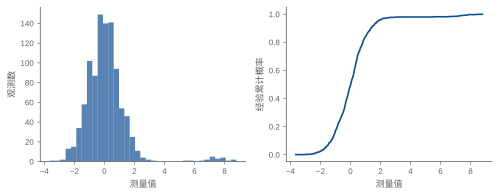

In [2]:
values = np.r_[rng.normal(size=980), rng.normal(7, 1, 20)]
print(pd.Series(values).describe(percentiles=[0.01, 0.5, 0.9, 0.99]))
print("均值/中位数/偏度:", values.mean(), np.median(values), stats.skew(values))
sorted_values = np.sort(values)
fig, axes = plt.subplots(1, 2, figsize=(7, 2.8))
axes[0].hist(values, bins=35, color=BLUE, alpha=0.7)
axes[0].set(xlabel="测量值", ylabel="观测数")
axes[1].step(sorted_values, np.arange(1, len(values) + 1) / len(values), where="post", color=BLUE)
axes[1].set(xlabel="测量值", ylabel="经验累计概率")
fig.tight_layout()
plt.show()

读法：少量尾部样本会拉动均值；ECDF 每次增加 1/n，直接表达阈值以下的比例。离散观测的重复值会形成更大的跳跃。

## 2. Pearson、Spearman 与非线性依赖

同一组 x 分别生成线性、单调非线性和对称抛物线响应，并估计连续互信息。

In [3]:
x = rng.uniform(-2, 2, 1800)
responses = {
    "linear": x + rng.normal(0, 0.2, len(x)),
    "monotone": np.exp(x) + rng.normal(0, 0.2, len(x)),
    "quadratic": x * x + rng.normal(0, 0.2, len(x)),
}
rows = []
for name, y in responses.items():
    rows.append(
        [
            name,
            pearsonr(x, y).statistic,
            spearmanr(x, y).statistic,
            mutual_info_regression(x[:, None], y, random_state=42)[0],
        ]
    )
print(pd.DataFrame(rows, columns=["response", "Pearson", "Spearman", "MI nats"]))
assert abs(pearsonr(x, responses["quadratic"]).statistic) < 0.15

    response   Pearson  Spearman   MI nats
0     linear  0.985679  0.986214  1.743951
1   monotone  0.895373  0.965740  1.845457
2  quadratic  0.040908  0.026271  1.600554


读法：抛物线有强依赖，却可有接近零的线性相关和秩相关。互信息估计值受样本量、邻居数和噪声影响，不能把它解释成因果效应或统一百分比。

## 3. 分组后重新看关联

让两组内部响应都随 x 上升，但组间截距与 x 的分布方向相反，观察聚合相关的反转。

总体相关: -0.8216387066814008
组内相关: group
0    0.771012
1    0.845121
dtype: float64


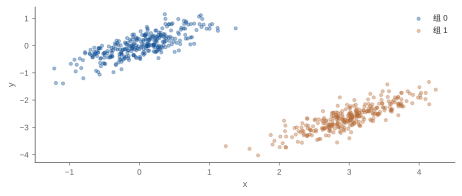

In [4]:
group = np.repeat([0, 1], 300)
x = rng.normal(3 * group, 0.5)
y = 0.8 * x - 5 * group + rng.normal(0, 0.25, len(x))
table = pd.DataFrame({"group": group, "x": x, "y": y})
print("总体相关:", table[["x", "y"]].corr().iloc[0, 1])
print("组内相关:", table.groupby("group").apply(lambda t: t.x.corr(t.y), include_groups=False))
fig, ax = plt.subplots(figsize=(6.5, 2.8))
for g, color in [(0, BLUE), (1, ORANGE)]:
    t = table[table.group == g]
    ax.scatter(t.x, t.y, s=10, alpha=0.35, color=color, label=f"组 {g}")
ax.set(xlabel="x", ylabel="y")
ax.legend()
fig.tight_layout()
plt.show()

读法：总体与条件关系回答不同问题；分组的理由来自采集过程，不能为了得到预期方向而任意挑组。这里的反转由已知合成机制产生。

## 4. 降维图与邻域保留

先标准化，再比较 PCA 与两种困惑度的 t-SNE；用 trustworthiness 检查低维邻域，而不凭视觉给簇命名。

PCA 邻域保真: 0.8757795838751625
t-SNE p=10 邻域保真: 0.9966521456436931
t-SNE p=40 邻域保真: 0.9958550065019506


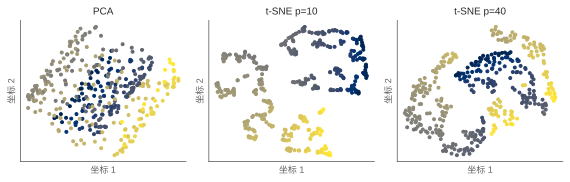

In [5]:
X, position = make_swiss_roll(n_samples=400, noise=0.15, random_state=42)
X = StandardScaler().fit_transform(X)
embeddings = {"PCA": PCA(n_components=2).fit_transform(X)}
for perplexity in (10, 40):
    embeddings[f"t-SNE p={perplexity}"] = TSNE(
        n_components=2,
        perplexity=perplexity,
        init="pca",
        learning_rate="auto",
        max_iter=500,
        random_state=42,
    ).fit_transform(X)
fig, axes = plt.subplots(1, 3, figsize=(8, 2.6))
for ax, (name, z) in zip(axes, embeddings.items(), strict=True):
    ax.scatter(z[:, 0], z[:, 1], c=position, cmap="cividis", s=9)
    ax.set(title=name, xlabel="坐标 1", ylabel="坐标 2", xticks=[], yticks=[])
    print(name, "邻域保真:", trustworthiness(X, z, n_neighbors=10))
fig.tight_layout()
plt.show()

读法：颜色仅用于追踪已知合成流形位置；t-SNE 的坐标轴没有原始物理单位，簇间距离和空白区域不能直接解释为自由能或结构差异。

## 小结

EDA 的核心是建立数据结构、统计摘要与图形证据之间的对应。先看观测单位和分布，再判断关联形式，最后用敏感性分析限制图形解释的范围。它为模型选择提出假设，也为后续验证提供需要单独检查的分组和边界。